<span style="font-family: Times New Roman; font-size: 32px; color: black; font-weight: bold;">EVALUATION SOMMATIVE UA3 </span>

<span style="font-family: Times New Roman; font-size: 24px; color: brown; font-weight: bold;">ANALYSE DES DONNÉES SUR LE DIABETES -- JUILLET 2025 </span>

# **Contexte**

Afin d’améliorer la détection du diabète au sein de la population, deux laboratoires ont mené des recherches à partir de deux ensembles de données différents issus de rapports médicaux de patients.

* Le premier laboratoire a mis en place un système de classification automatique des
patients en trois catégories :
1. Pas de diabète
2. Risque de diabète
3. Diabète confirmé

* Le deuxième laboratoire, quant à lui, a développé une technologie permettant de collecter les données médicales des patients sans les classer. Selon leurs analyses, une classification binaire en deux grands groupes (diabétique / non diabétique) serait plus pertinente.


# **Problème**

Malgré l’implémentation de modèles d’apprentissage automatique dans chacun des laboratoires, les résultats obtenus divergent. Les deux équipes sollicitent votre expertise en sciences des données afin de proposer une solution de classification adaptée aux deux types de données.

# **Origine et Nature des données**

| Attribut | Type | Valeurs possibles | Description (traduite) |
| :--- | :--- | :--- | :--- |
| **HighBP** | Binaire | 0 ou 1 | Présence d’hypertension artérielle |
| **HighChol** | Binaire | 0 ou 1 | Présence d’un taux de cholestérol élevé |
| **CholCheck** | Binaire | 0 ou 1 | Contrôle du cholestérol au cours des 5 dernières années |
| **BMI** | Entier | 12‑98 | Indice de masse corporelle (IMC) |
| **Smoker** | Binaire | 0 ou 1 | A fumé au moins 100 cigarettes dans sa vie |
| **Stroke** | Binaire | 0 ou 1 | A déjà subi un accident vasculaire cérébral |
| **HeartDiseaseorAttack** | Binaire | 0 ou 1 | Antécédent de maladie coronarienne ou infarctus |
| **PhysActivity** | Binaire | 0 ou 1 | Pratique d’une activité physique dans les 30 jours |
| **Fruits** | Binaire | 0 ou 1 | Consomme des fruits au moins une fois par jour |
| **Veggies** | Binaire | 0 ou 1 | Consomme des légumes au moins une fois par jour |
| **HvyAlcoholConsump** | Binaire | 0 ou 1 | Consommation excessive d’alcool : ≥ 14 boissons/semaine pour les hommes et ≥ 7 pour les femmes |
| **AnyHealthcare** | Binaire | 0 ou 1 | Bénéficie d’une couverture santé (assurance, …) |
| **NoDocbcCost** | Binaire | 0 ou 1 | N’a pas pu consulter un médecin l’année précédente pour des raisons de coût |
| **GenHlth** | Entier | 1‑5 | Évalue la santé générale de 1 (excellente) à 5 (mauvaise) |
| **MentHlth** | Entier | 0‑30 | Nombre de jours de mauvaise santé mentale durant le dernier mois |
| **PhysHlth** | Entier | 0‑30 | Nombre de jours de mauvaise santé physique ou blessure durant le dernier mois |
| **DiffWalk** | Binaire | 0 ou 1 | Difficulté à marcher ou à monter des escaliers |
| **Sex** | Binaire | 0 ou 1 | Sexe de la personne (0 = femme, 1 = homme) |
| **Age** | Entier | 1‑13 | Tranche d’âge en 13 catégories (croissante) |
| **Education** | Entier | 1‑6 | Niveau d’éducation en 6 catégories (1 = aucun diplôme, 6 = bac+4) |
| **Income** | Entier | 1‑8 | Catégorie de revenu en 8 niveaux croissants |

# **Traitement des données**

In [1]:
!pip install kmodes


[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: C:\Users\mirma\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [2]:
import sys
!{sys.executable} -m pip install kmodes

In [3]:

# Importation des bibliothéques 
import pandas as pd
import numpy as np
from kmodes.kprototypes import KPrototypes
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split



# **Diagnostic des données**

### Données du LABO 1 

In [4]:
lab1 = pd.read_csv("diabete_labo1.csv")

In [5]:
lab1.head(10)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0
5,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,2.0,0.0,1.0,10.0,6.0,8.0
6,0.0,1.0,0.0,1.0,30.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,3.0,0.0,14.0,0.0,0.0,9.0,6.0,7.0
7,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,1.0,0.0,11.0,4.0,4.0
8,2.0,1.0,1.0,1.0,30.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,5.0,30.0,30.0,1.0,0.0,9.0,5.0,1.0
9,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,8.0,4.0,3.0


In [6]:
lab1.shape

(253680, 22)

In [7]:
lab1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [8]:
lab1.describe()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.296921,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.698160,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,2.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


In [9]:
# Distribution de la variable cible
lab1["Diabetes_012"].value_counts()

Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64

In [10]:
lab1.duplicated().sum()

23899

Le premier diagnostic des données issues du laboratoire 1 revele la présence de 253680 observations pour 22 variables. Du premier coup d'oeil on observe aucune présence de valeurs manquantes, et toutes les variables sont numérisés. 

D'un point de vue statistisques certaines variables présentes des écarts types élevés suggérant une  forte dispersion des données (MentHlth, BMI, PhysHlth). Autre point la plupart des variables n'ont que 2 valeurs représentatifs soit 0 ou 1.

On note également une forte représentativité de la valeur 0 dans la variable cible suggérant une imbalance des classes.

### Données du LABO 2

In [11]:
lab2 = pd.read_csv("diabete_labo2.csv")

In [12]:
lab2.head(10)

,Unnamed: 0,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0
5,5,0.0,0.0,1.0,18.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,2.0,7.0,0.0,0.0,0.0,1.0,4.0,7.0
6,6,0.0,1.0,1.0,26.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0,5.0,6.0
7,7,0.0,0.0,1.0,31.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,4.0,0.0,0.0,0.0,1.0,6.0,4.0,3.0
8,8,0.0,0.0,1.0,32.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,0.0,3.0,6.0,8.0
9,9,0.0,0.0,1.0,27.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,6.0,0.0,1.0,6.0,4.0,4.0


In [13]:
lab2.shape

(70692, 22)

In [14]:
lab2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            70692 non-null  int64  
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  MentHlth           

In [15]:
lab2.describe()

,Unnamed: 0,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,...,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000
mean,35345.500000,0.563458,0.525703,0.975259,29.856985,0.475273,0.062171,0.147810,0.703036,0.611795,...,0.954960,0.093914,2.837082,3.752037,5.810417,0.252730,0.456997,8.584055,4.920953,5.698311
std,20407.166952,0.495960,0.499342,0.155336,7.113954,0.499392,0.241468,0.354914,0.456924,0.487345,...,0.207394,0.291712,1.113565,8.155627,10.062261,0.434581,0.498151,2.852153,1.029081,2.175196
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,17672.750000,0.000000,0.000000,1.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,7.000000,4.000000,4.000000
50%,35345.500000,1.000000,1.000000,1.000000,29.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,9.000000,5.000000,6.000000
75%,53018.250000,1.000000,1.000000,1.000000,33.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,4.000000,2.000000,6.000000,1.000000,1.000000,11.000000,6.000000,8.000000
max,70691.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


In [16]:
lab2.duplicated().sum()

0

Le diagnostic des données du laboratoire 2 nous revele un dataset de 70692 observations pour 22 variables. À la différence du premier jeux, ce dataset ne posséde pas de variable cible. Le reste des variables est similaire au premier jeux de données. 

Autre similarité, la plupart des variables sont representés par 2 valeurs soit 0 et 1, et aussi on observe une forte dispersion.

### Fusion des jeux de données

**Méthodologie:**

Comme chaque jeux de données a déjà été soumis a des modèles d'apprentissage par chaque laboratoire avec des résultats divergents, on va procéder à un jumellage de nos deux sets qu'on va nettoyer, puis clustériser, avant de soumettre les données du lab1 à l'entrainement et au test. Le modéle arborant les meilleurs résultats sera utilisé comme référence pour la prédiction sur les données non étiquetées. À la suite de cela ces valeurs prédictifs seront croisés avec nos clusters pour voir si il y a une relation.

In [17]:
# Rappel des colonnes de chaque datasets
print("Les colonnes du 1er dataset: ", lab1.columns)
print("Les colonnes du 2ème dataset: ", lab2.columns)

Les colonnes du 1er dataset:  Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='object')
Les colonnes du 2ème dataset:  Index(['Unnamed: 0', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='object')


In [18]:
# 1. Sauvegarde de la variable cible pour 
var_cible = lab1[['Diabetes_012']].copy()

# 2. Supprimer la colonne 'Unnamed: 0' du dataset 2 
df2 = lab2.drop(columns=['Unnamed: 0'], errors='ignore').copy()

# 3. Copie du dataset 1
df1 = lab1.copy()

# 4. Ajout d'une colonne source pour la provenance de la donnée
df1["Source"] = "etiquete"
df2["Source"] = "non_etiquete"

# 5. Alignement des valeurs nulles pour la colonne Diabetes_012 des données du labo 2
df2['Diabetes_012'] = np.nan

# 6. S'assurer que le type de la colonne cible est strictement identique (float64) sur les deux
df1["Diabetes_012"] = df1["Diabetes_012"].astype(float)
df2["Diabetes_012"] = df2["Diabetes_012"].astype(float)

# 5. Concaténer les deux datasets verticalement (les mettre bout à bout)
df = pd.concat([df1, df2], ignore_index=True)

print("Forme du dataset final après concaténation :", df.shape)

Forme du dataset final après concaténation : (324372, 23)


In [19]:
# Répartition des valeurs dans la colonne cible du nouveau dataset
df['Diabetes_012'].value_counts(dropna=False)

Diabetes_012
0.0    213703
NaN     70692
2.0     35346
1.0      4631
Name: count, dtype: int64

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 324372 entries, 0 to 324371
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                324372 non-null  float64
 2   HighChol              324372 non-null  float64
 3   CholCheck             324372 non-null  float64
 4   BMI                   324372 non-null  float64
 5   Smoker                324372 non-null  float64
 6   Stroke                324372 non-null  float64
 7   HeartDiseaseorAttack  324372 non-null  float64
 8   PhysActivity          324372 non-null  float64
 9   Fruits                324372 non-null  float64
 10  Veggies               324372 non-null  float64
 11  HvyAlcoholConsump     324372 non-null  float64
 12  AnyHealthcare         324372 non-null  float64
 13  NoDocbcCost           324372 non-null  float64
 14  GenHlth               324372 non-null  float64
 15  

## Nettoyage des données

In [21]:
def nettoyer_et_analyser_dataset(df, nom_dataset="Dataset"):
    print(f"\n{'='*20} TRAITEMENT : {nom_dataset} {'='*20}")
    
    # Copie pour éviter de modifier l'original par inadvertance
    df_propre = df.copy()
    
    # ----------------------------------------------------
    # 1. GESTION DES VALEURS MANQUANTES
    # ----------------------------------------------------
    print("\n--- 1. Recherche des valeurs manquantes ---")
    nb_valeurs_manquantes = df_propre.isnull().sum()
    
    if nb_valeurs_manquantes.sum() == 0:
        print("Aucune valeur manquante détectée.")
    else:
        print("Valeurs manquantes trouvées par variable :")
        print(nb_valeurs_manquantes[nb_valeurs_manquantes > 0])
        
    # ----------------------------------------------------
    # 2. GESTION DES DOUBLONS
    # ----------------------------------------------------
    print("\n--- 2. Recherche des doublons ---")

    nb_doublons = df_propre.duplicated().sum()

    if nb_doublons == 0:
        print("Aucun doublon détecté.")
    else:
        print(f"{nb_doublons} ligne(s) en double détectée(s).")

        # Suppression des doublons
        df_propre = df_propre.drop_duplicates()
        print("-> Les doublons ont été supprimés.") 
        
    # ----------------------------------------------------
    # 3. VÉRIFICATION DES VALEURS ABERRANTES (Sans suppression)
    # ----------------------------------------------------
    print("\n--- 3. Vérification des valeurs aberrantes (Méthode IQR) ---")
    colonnes_numeriques = df_propre.select_dtypes(include=[np.number]).columns
    
    total_outliers_trouves = 0
    for col in colonnes_numeriques:
        Q1 = df_propre[col].quantile(0.25)
        Q3 = df_propre[col].quantile(0.75)
        IQR = Q3 - Q1
        
        borne_inf = Q1 - 1.5 * IQR
        borne_sup = Q3 + 1.5 * IQR
        
        outliers = df_propre[(df_propre[col] < borne_inf) | (df_propre[col] > borne_sup)]
        
        if not outliers.empty:
            print(f"  - Variable '{col}' : {len(outliers)} valeur(s) aberrante(s) potentielle(s) détectée(s) (hors intervalle [{borne_inf:.2f}, {borne_sup:.2f}]).")
            total_outliers_trouves += len(outliers)
            
    if total_outliers_trouves == 0:
        print("Aucune valeur aberrante détectée sur l'ensemble des variables numériques.")
    else:
        print("-> Rappel : Les valeurs aberrantes ont été uniquement vérifiées et n'ont PAS été supprimées.")
        
    print(f"\n{'='*20} FIN DU TRAITEMENT : {nom_dataset} {'='*20}\n")
    return df_propre



In [22]:
lab = nettoyer_et_analyser_dataset(df, "Dataset")


==================== TRAITEMENT : Dataset ====================

--- 1. Recherche des valeurs manquantes ---
Valeurs manquantes trouvées par variable :
Diabetes_012    70692
dtype: int64

--- 2. Recherche des doublons ---


25942 ligne(s) en double détectée(s).
-> Les doublons ont été supprimés.

--- 3. Vérification des valeurs aberrantes (Méthode IQR) ---
  - Variable 'Diabetes_012' : 39726 valeur(s) aberrante(s) potentielle(s) détectée(s) (hors intervalle [0.00, 0.00]).
  - Variable 'CholCheck' : 11038 valeur(s) aberrante(s) potentielle(s) détectée(s) (hors intervalle [1.00, 1.00]).
  - Variable 'BMI' : 8191 valeur(s) aberrante(s) potentielle(s) détectée(s) (hors intervalle [12.00, 44.00]).
  - Variable 'Stroke' : 14679 valeur(s) aberrante(s) potentielle(s) détectée(s) (hors intervalle [0.00, 0.00]).
  - Variable 'HeartDiseaseorAttack' : 34124 valeur(s) aberrante(s) potentielle(s) détectée(s) (hors intervalle [0.00, 0.00]).
  - Variable 'Veggies' : 62045 valeur(s) aberrante(s) potentielle(s) détectée(s) (hors intervalle [1.00, 1.00]).
  - Variable 'HvyAlcoholConsump' : 16954 valeur(s) aberrante(s) potentielle(s) détectée(s) (hors intervalle [0.00, 0.00]).
  - Variable 'AnyHealthcare' : 15574 valeur(s) a

In [23]:
# Dataset Lab1 avant et aprés traietement
print("Dataset Avant traitement: " , df.shape)
print("Dataset Après traitement: ", lab.shape)
print(lab['Diabetes_012'].value_counts(dropna=False))

Dataset Avant traitement:  (324372, 23)
Dataset Après traitement:  (298430, 23)
Diabetes_012
0.0    190055
NaN     68649
2.0     35097
1.0      4629
Name: count, dtype: int64


À la suite des opérations de prétraitement, le jeu de données fusionné a mis en évidence 25 942 doublons, représentant environ 7,9 % du volume global. Ces doublons complets ayant été identifiés, il a été procédé à leur suppression.

Concernant la variable cible, l'analyse initiale recensait 70 692 valeurs manquantes, ce qui correspondait au volume attendu pour les données non étiquetées issues du second laboratoire (Lab 2). Toutefois, après application du nettoyage, ce nombre s'est établi à **68 649 lignes**, soit un écart de **2 043 enregistrements**.

Cet écart met en lumière un phénomène de chevauchement (*overlap*) lors de la concaténation des sources : **2 043 profils du Lab 2 étaient identiques à des données déjà présentes dans le Lab 1**. En tenant compte des doublons internes propres au Lab 1 (au nombre de 23 899), l'addition de ces doublons inter-datasets ($23\,899 + 2\,043$) justifie mathématiquement et explique le total final de **25 942** doublons supprimés.

In [24]:
lab.columns

Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income',
       'Source'],
      dtype='object')

# **Analyse exploratoire des données et Visualisation**

## Distribution du jeu de données

# **Transformation du jeux de donnée**

Aprés nettoyage des données, notre dataset compte beaucoup de valeurs aberrantes. La plupart des variables étant binaires, la présence de valeurs aberrantes suggére essentiellement la domination d'une classe par rapport à l'autre. À cause de cela on ne peut les supprimer, ni les ignorer completement de peur de perdre une information critique. 

Pour conserver ces profils tout en évitant que notre modélisation ne soit biaisé, on va procéder à la winsorisation ou capping; ie que on va modifier la valeur excessive de la variable de sorte à ce qu'elle respecte une borne acceptable

In [25]:
def winsoriser_dataset(df, colonnes_cibles):
    """
    Remplace les valeurs aberrantes par les bornes min/max (IQR) 
    sans supprimer les lignes.
    """
    df_winsor = df.copy()
    
    print("--- Application de la Winsorisation ---")
    for col in colonnes_cibles:
        if col in df_winsor.columns:
            Q1 = df_winsor[col].quantile(0.25)
            Q3 = df_winsor[col].quantile(0.75)
            IQR = Q3 - Q1
            
            borne_inf = Q1 - 1.5 * IQR
            borne_sup = Q3 + 1.5 * IQR
            
            # Comptage des valeurs concernées avant modification
            nb_inf = (df_winsor[col] < borne_inf).sum()
            nb_sup = (df_winsor[col] > borne_sup).sum()
            
            # Plafonnement (remplacement par les bornes)
            df_winsor[col] = np.where(df_winsor[col] < borne_inf, borne_inf, df_winsor[col])
            df_winsor[col] = np.where(df_winsor[col] > borne_sup, borne_sup, df_winsor[col])
            
            print(f"Variable '{col}' : {nb_inf} valeur(s) trop basse(s) plafonnée(s) à {borne_inf:.2f} | {nb_sup} valeur(s) trop haute(s) plafonnée(s) à {borne_sup:.2f}")
            
    print("---------------------------------------")
    return df_winsor

# ====================================================
# EXÉCUTION 
# ====================================================
# Spécifiez ici vos 4 variables non binaires (ou adaptez les noms selon vos colonnes)
variables_a_winsoriser = ['BMI', 'MentHlth', 'PhysHlth']

df_winsor = winsoriser_dataset(lab, variables_a_winsoriser)

--- Application de la Winsorisation ---
Variable 'BMI' : 0 valeur(s) trop basse(s) plafonnée(s) à 12.00 | 8191 valeur(s) trop haute(s) plafonnée(s) à 44.00
Variable 'MentHlth' : 0 valeur(s) trop basse(s) plafonnée(s) à -3.00 | 47979 valeur(s) trop haute(s) plafonnée(s) à 5.00
Variable 'PhysHlth' : 0 valeur(s) trop basse(s) plafonnée(s) à -6.00 | 47933 valeur(s) trop haute(s) plafonnée(s) à 10.00
---------------------------------------


In [26]:
df_winsor.columns

Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income',
       'Source'],
      dtype='object')

**Rappel**

Notre objectif pricnipal est de concevoir un modèle prédictif du diabète à l'aide des jeux de données provenant de 2 laboratoires différents. Un set de données est étiquetée (lab1), et un autre set ne l'est pas (lab2). Pour surmonter la complexité des données et structuré notre approche nous avons adopté une méthodologie en 2 phases complementaire: 
* 1. Une pase non supervisé d'exploration
* 2. Une phase supervisé de modélisation prédictive

## Clustering via K-Prototypes

Il s'agit de répartir notre dataset en groupes distincts, pour cela nous utilisons l'algorithme du K-prototypes qui va éviter tout biais d'apprentissage et va permettre de classer les profils des patients de maniére totalement objective. Pour plus d'objectivité les variables Diabetes_012 (variable cible), et source seront exclus.

In [27]:
# 1. Préparation des données pour le clustering
colonnes_a_exclure = ['Diabetes_012', 'Source'] 
features_clustering = [
    col for col in df_winsor.columns if col not in colonnes_a_exclure
]

# Jeu de donnée pour le clustering
X_cluster = df_winsor[features_clustering].copy()

# 2. Définition des variables numériques vs catégorielles/binaires
# Les variables continues ou comptages principaux :
colonnes_numeriques = ['BMI', 'MentHlth', 'PhysHlth']

# 3. Récupérer les indices (positions) des colonnes catégorielles pour K-Prototypes
cat_indices = [
    X_cluster.columns.get_loc(col) for col in X_cluster.columns if col not in colonnes_numeriques
    ]

# 4. Convertir le DataFrame en matrice numpy (requis par la bibliothèque kmodes)
data_matrice = X_cluster.to_numpy()

# 5. Initialisation et entraînement du modèle K-Prototypes
# Choisissons par exemple k = 4 clusters (profils de santé types)
k = 3
print(f"Lancement du K-Prototypes avec k = {k} clusters...")

kproto = KPrototypes(n_clusters=k, init='Cao', n_init=5, random_state=42)
clusters = kproto.fit_predict(data_matrice, categorical=cat_indices)

# 6. Ajouter les résultats des clusters dans votre DataFrame
df_winsor['Cluster'] = clusters

print("\n--- EClustering terminé avec succès ! ---")

# Afficher la répartition des individus par cluster
print("\nRépartition des profils par cluster :")
print(df_winsor['Cluster'].value_counts().sort_index())

Lancement du K-Prototypes avec k = 3 clusters...



--- EClustering terminé avec succès ! ---

Répartition des profils par cluster :
Cluster
0     75368
1    170596
2     52466
Name: count, dtype: int64


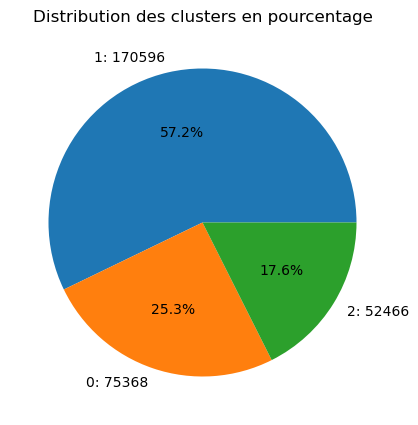

In [28]:
fig = plt.figure(figsize=(5, 5))

data = df_winsor['Cluster'].value_counts()

labels = [f'{cluster}: {count}'
          for cluster, count in data.items()]

plt.pie(
    data.values,
    labels=labels,
    autopct='%1.1f%%'
)

plt.title('Distribution des clusters en pourcentage')
plt.show()

In [29]:
# Analyse déterminante pour chaque cluster 
# Moyenne par proportion de chaque variables pour chaque cluster
df_winsor.columns

Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income',
       'Source', 'Cluster'],
      dtype='object')

In [30]:
df_winsor.info()

<class 'pandas.core.frame.DataFrame'>
Index: 298430 entries, 0 to 324371
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          229781 non-null  float64
 1   HighBP                298430 non-null  float64
 2   HighChol              298430 non-null  float64
 3   CholCheck             298430 non-null  float64
 4   BMI                   298430 non-null  float64
 5   Smoker                298430 non-null  float64
 6   Stroke                298430 non-null  float64
 7   HeartDiseaseorAttack  298430 non-null  float64
 8   PhysActivity          298430 non-null  float64
 9   Fruits                298430 non-null  float64
 10  Veggies               298430 non-null  float64
 11  HvyAlcoholConsump     298430 non-null  float64
 12  AnyHealthcare         298430 non-null  float64
 13  NoDocbcCost           298430 non-null  float64
 14  GenHlth               298430 non-null  float64
 15  MentH

In [31]:
# Calculer la moyenne uniquement sur les colonnes numériques
profils_clusters = df_winsor.groupby('Diabetes_012').mean(numeric_only=True)

# Sélectionner quelques variables clés de santé pour un premier aperçu rapide
variables_cles = ['HighBP', 'HighChol', 'BMI', 'Smoker', 'HeartDiseaseorAttack', 'GenHlth', 'Age']
print(profils_clusters[variables_cles])

                HighBP  HighChol        BMI    Smoker  HeartDiseaseorAttack  \
Diabetes_012                                                                  
0.0           0.395175  0.395349  27.848375  0.455110              0.079961   
1.0           0.629078  0.620868  30.438108  0.492763              0.143444   
2.0           0.752344  0.669459  31.562869  0.519218              0.223837   

               GenHlth       Age  
Diabetes_012                      
0.0           2.463724  7.824230  
1.0           2.976021  9.082091  
2.0           3.295894  9.375958  


Aprés le clustering notre dataset a été regroupés suivant 3 profils différents. 

* **Cluster 0** : selon cette analyse regroupe le groupe qui pr.sente les taux les plus bas en hypertension, cholestérol, BMI, et risques de problémes cardiaques. La santé général est percue comme la meilleure. On peut en déduire que c'est le groupe sain.

* **Cluster 1** : selon cette analyse regroupe les taux nettement supérieurs mais pas le maximun. Que ce soit pour l'hypertension, le cholestérol, le BMI ou la santé général n'est pas mauvaise. On les met comme profils à risque.

* **Cluster 2** : ce profil est à haut risque vu qu'il affiche les risques élevé de hypertension, cholestérol, incidences cardiaques, âge, BMI. 

# **Machine Learning**

## **Random Forest**

In [32]:
# 1. Séparation des données 
# Partie étiquetée
df_etiquete = df_winsor[df_winsor['Diabetes_012'].notna()].copy()
# Partie non-étiquetée
df_non_etiquete = df_winsor[df_winsor['Diabetes_012'].isna()].copy()

In [33]:
# 2. Préparation de X et y pour l'entrainement et le test
features_modele = [
    col
    for col in df_etiquete.columns
    if col not in ['Diabetes_012', 'Source'] # Ce dataset prend en compte toutes les variables sauf celle de la variable cible et de la provenance du jeux de données
]

X = df_etiquete[features_modele]
y = df_etiquete['Diabetes_012']

In [34]:
# 3. Découpage du set soit 80% pour l'entrainement et 20% pour l'évaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [35]:
# 4. Entrainement du modéle

poids_sur_mesure = {0.0:1.0, 1.0:5.0, 2.0:2.0}

rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight=poids_sur_mesure
)
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight={0.0: 1.0, 1.0: 5.0, 2.0: 2.0},
                       random_state=42)


--- Rapport de Classification (Évaluation) ---
              precision    recall  f1-score   support

         0.0       0.85      0.96      0.90     38012
         1.0       0.00      0.00      0.00       926
         2.0       0.47      0.19      0.27      7019

    accuracy                           0.82     45957
   macro avg       0.44      0.38      0.39     45957
weighted avg       0.77      0.82      0.79     45957



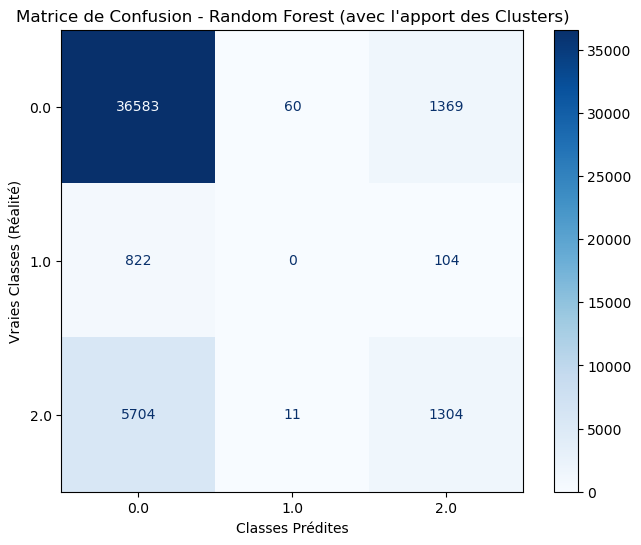

In [36]:
# 5. Évaluation sur test et matrice de confusion
y_pred = rf_model.predict(X_test)
print("\n--- Rapport de Classification (Évaluation) ---")
print(classification_report(y_test, y_pred))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)

# Affichage graphique de la matrice de confusion
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_,  # Affiche les classes de Diabetes_012 (ex: 0.0, 1.0, 2.0)
)

disp.plot(cmap=plt.cm.Blues, ax=ax, values_format="d")
plt.title(
    "Matrice de Confusion - Random Forest (avec l'apport des Clusters)"
)
plt.xlabel("Classes Prédites")
plt.ylabel("Vraies Classes (Réalité)")
plt.show()

## **XGBoost**

--- Entraînement du modèle XGBoost ---
Modèle XGBoost entraîné avec succès !

--- Rapport de Classification (XGBoost) ---
              precision    recall  f1-score   support

         0.0       0.94      0.64      0.76     38012
         1.0       0.03      0.25      0.06       926
         2.0       0.35      0.63      0.45      7019

    accuracy                           0.63     45957
   macro avg       0.44      0.51      0.42     45957
weighted avg       0.83      0.63      0.70     45957



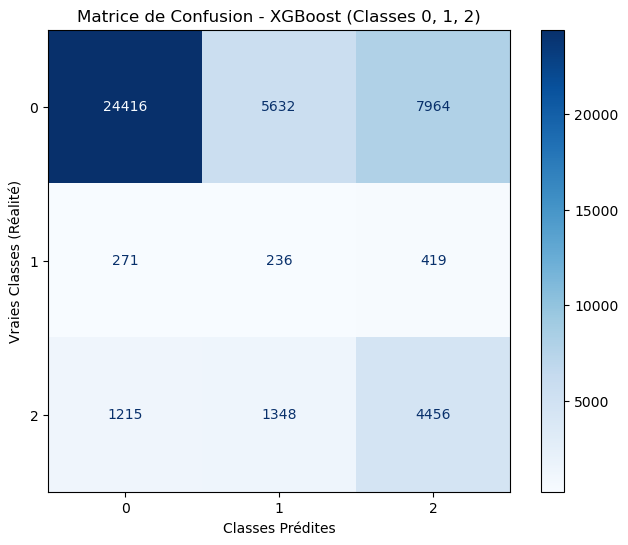

In [37]:
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# 1. Calcul des poids d'échantillons pour rééquilibrer les classes (multiclasse)
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

# 2. Initialisation et entraînement du modèle XGBoost
print("--- Entraînement du modèle XGBoost ---")
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    eval_metric="mlogloss",  # Évite les avertissements sur la perte multiclasse
)

# On entraîne en intégrant les poids calculés pour forcer le modèle à voir les classes rares
xgb_model.fit(X_train, y_train, sample_weight=sample_weights)
print("Modèle XGBoost entraîné avec succès !")

# 3. Prédiction sur le jeu de test
y_pred_xgb = xgb_model.predict(X_test)

print("\n--- Rapport de Classification (XGBoost) ---")
print(classification_report(y_test, y_pred_xgb))

# 4. Affichage de la matrice de confusion
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb, display_labels=xgb_model.classes_
)
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format="d")
plt.title("Matrice de Confusion - XGBoost (Classes 0, 1, 2)")
plt.xlabel("Classes Prédites")
plt.ylabel("Vraies Classes (Réalité)")
plt.show()

--- Entraînement de XGBoost (Version Affinée) ---
Modèle affiné avec succès !

--- Rapport de Classification (XGBoost Affiné) ---
              precision    recall  f1-score   support

         0.0       0.95      0.62      0.75     38012
         1.0       0.03      0.31      0.06       926
         2.0       0.36      0.62      0.46      7019

    accuracy                           0.62     45957
   macro avg       0.45      0.52      0.42     45957
weighted avg       0.84      0.62      0.69     45957



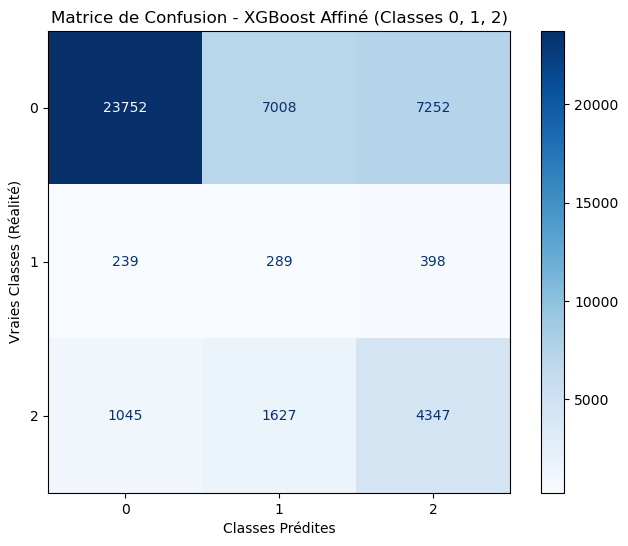

In [38]:
# Affinage du modéle et entrainement

# 1. Calcul des poids d'échantillons
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

# 2. Configuration d'un XGBoost affiné et régularisé
print("--- Entraînement de XGBoost (Version Affinée) ---")
xgb_model_tuned = XGBClassifier(
    n_estimators=150,
    max_depth=5,            # Arbres un peu moins profonds pour limiter le surapprentissage
    learning_rate=0.05,     # Apprentissage plus progressif
    subsample=0.8,          # Utilisation de 80% des lignes par arbre
    colsample_bytree=0.8,   # Utilisation de 80% des colonnes par arbre
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss'
)

# Entraînement avec les poids d'équilibrage
xgb_model_tuned.fit(X_train, y_train, sample_weight=sample_weights)
print("Modèle affiné avec succès !")

# 3. Prédictions sur le jeu de test
y_pred_tuned = xgb_model_tuned.predict(X_test)

print("\n--- Rapport de Classification (XGBoost Affiné) ---")
print(classification_report(y_test, y_pred_tuned))

# 4. Affichage de la matrice de confusion
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tuned, display_labels=xgb_model_tuned.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Matrice de Confusion - XGBoost Affiné (Classes 0, 1, 2)")
plt.xlabel("Classes Prédites")
plt.ylabel("Vraies Classes (Réalité)")
plt.show()


## **Catboost**
plus adapté aux déséquilibre des classes dans les données

In [39]:
!pip install catboost


[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: C:\Users\mirma\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [40]:
import sys
!{sys.executable} -m pip install catboost

--- Entraînement du modèle CatBoost ---
0:	learn: 1.0880446	total: 226ms	remaining: 45.1s
50:	learn: 0.9644285	total: 3.48s	remaining: 10.2s
100:	learn: 0.9475811	total: 7.26s	remaining: 7.12s
150:	learn: 0.9380528	total: 11.9s	remaining: 3.85s
199:	learn: 0.9308992	total: 15.5s	remaining: 0us
Modèle CatBoost entraîné avec succès !

--- Rapport de Classification (CatBoost) ---
              precision    recall  f1-score   support

         0.0       0.95      0.63      0.76     38012
         1.0       0.03      0.32      0.06       926
         2.0       0.37      0.61      0.46      7019

    accuracy                           0.62     45957
   macro avg       0.45      0.52      0.42     45957
weighted avg       0.84      0.62      0.70     45957



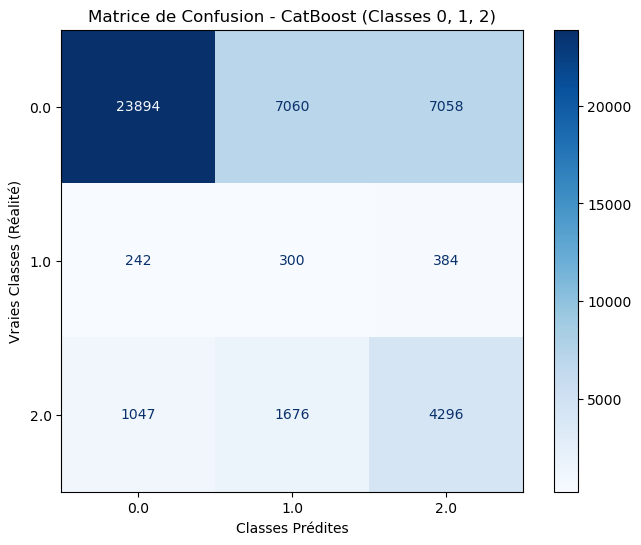

In [41]:
from catboost import CatBoostClassifier

# 1. Initialisation et configuration de CatBoost
# 'auto_class_weights="Balanced"' gère automatiquement le déséquilibre en multiclasse
print("--- Entraînement du modèle CatBoost ---")
cat_model = CatBoostClassifier(
    iterations=200,            # Nombre d'arbres (itérations)
    learning_rate=0.05,        # Taux d'apprentissage progressif
    depth=6,                   # Profondeur des arbres
    auto_class_weights='Balanced', # Équilibrage automatique des classes 0, 1 et 2
    random_seed=42,
    verbose=50                 # Affiche la progression tous les 50 arbres
)

# 2. Entraînement sur le jeu d'entraînement (X_train, y_train)
cat_model.fit(X_train, y_train)
print("Modèle CatBoost entraîné avec succès !")

# 3. Prédiction sur le jeu de test
y_pred_cat = cat_model.predict(X_test)

# CatBoost retourne parfois un tableau 2D pour les prédictions, on s'assure de l'aplatir si besoin
if y_pred_cat.ndim > 1:
    y_pred_cat = y_pred_cat.flatten()

print("\n--- Rapport de Classification (CatBoost) ---")
print(classification_report(y_test, y_pred_cat))

# 4. Affichage de la matrice de confusion
cm_cat = confusion_matrix(y_test, y_pred_cat)
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_cat, display_labels=cat_model.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Matrice de Confusion - CatBoost (Classes 0, 1, 2)")
plt.xlabel("Classes Prédites")
plt.ylabel("Vraies Classes (Réalité)")
plt.show()

## **Tableau comparatif des performances des Modèles**

In [42]:

# 1. Regroupez vos modèles entraînés dans un dictionnaire
# (Assurez-vous d'utiliser les noms exacts des variables de vos modèles dans votre notebook)
models_dict = {
    "Random Forest": rf_model, 
    "XGBoost" : xgb_model,
    "XGBoost Affiné": xgb_model_tuned,
    "CatBoost": cat_model,
}

comparison_data = []

# 2. Boucle d'évaluation automatique
for name, model in models_dict.items():
  # Prédiction sur le jeu de test
  y_pred = model.predict(X_test)

  # Nettoyage du format si le modèle retourne un tableau 2D (ex: CatBoost parfois)
  if hasattr(y_pred, "ndim") and y_pred.ndim > 1:
    y_pred = y_pred.flatten()

  # Extraction du rapport sous forme de dictionnaire grâce à output_dict=True
  report = classification_report(y_test, y_pred, output_dict=True)

  # Stockage des métriques pertinentes (focus sur la classe 1.0 et la moyenne globale)
  for classe in ["0.0", "1.0", "2.0"]:
    if classe in report:
      comparison_data.append({
          "Modèle": name,
          "Classe": classe,
          "Précision": round(report[classe]["precision"], 3),
          "Rappel (Recall)": round(report[classe]["recall"], 3),
          "F1-score": round(report[classe]["f1-score"], 3),
          "Support (Nb cas)": report[classe]["support"],
      })

# 3. Création et affichage du tableau récapitulatif
df_comparison = pd.DataFrame(comparison_data)

# Affichage esthétrique dans le notebook
print("--- TABLEAU COMPARATIF DES PERFORMANCES ---")
display(df_comparison)

--- TABLEAU COMPARATIF DES PERFORMANCES ---


,Modèle,Classe,Précision,Rappel (Recall),F1-score,Support (Nb cas)
0,Random Forest,0.0,0.849,0.962,0.902,38012.0
1,Random Forest,1.0,0.000,0.000,0.000,926.0
2,Random Forest,2.0,0.470,0.186,0.266,7019.0
3,XGBoost,0.0,0.943,0.642,0.764,38012.0
4,XGBoost,1.0,0.033,0.255,0.058,926.0
5,XGBoost,2.0,0.347,0.635,0.449,7019.0
6,XGBoost Affiné,0.0,0.949,0.625,0.753,38012.0
7,XGBoost Affiné,1.0,0.032,0.312,0.059,926.0
8,XGBoost Affiné,2.0,0.362,0.619,0.457,7019.0
9,CatBoost,0.0,0.949,0.629,0.756,38012.0


Suivant ce tableau de résultats on observe que Random Forest est totalement aveugle quant à la prédiction de la classe 1, ou prédiabéte. Le XGBoost par contre a de meilleure résultat même après affinage du modéle, mais le modéle du Catboost reste le meilleure dans la prédiction de chaque classe. On peut affiner notre recherche avec un modéle de deep learning pour une meilleure appréciation. 
Mais avant cela appliquons le modéle du Catboost sur les données non étiquetées.

## Application sur le dataset non etiquete

In [43]:
import pandas as pd

# 1. Extraction des features pour la partie non-étiquetée en utilisant vos variables
X_non_etiquete = df_non_etiquete[features_modele]

print(f"Nombre de lignes non étiquetées à prédire : {len(X_non_etiquete)}")

# 2. Génération des prédictions avec le modèle CatBoost optimal
y_pred_non_etiquete = cat_model.predict(X_non_etiquete)

# Aplatissement du tableau si CatBoost renvoie un format 2D
if hasattr(y_pred_non_etiquete, "ndim") and y_pred_non_etiquete.ndim > 1:
  y_pred_non_etiquete = y_pred_non_etiquete.flatten()

# 3. Attribution des prédictions prédites dans la colonne cible de df_non_etiquete
df_non_etiquete["Diabetes_012"] = y_pred_non_etiquete

# 4. Fusion finale pour recréer le grand dataset unifié complet
df_final_unified = pd.concat(
    [df_etiquete, df_non_etiquete], ignore_index=True
)

print("\n--- Fusion Réussie ! ---")
print(f"Taille totale du dataset unifié final : {df_final_unified.shape}")
print(
    "Répartition des classes dans le dataset final :\n",
    df_final_unified["Diabetes_012"].value_counts(),
)

Nombre de lignes non étiquetées à prédire : 68649

--- Fusion Réussie ! ---
Taille totale du dataset unifié final : (298430, 24)
Répartition des classes dans le dataset final :
 Diabetes_012
0.0    216940
2.0     62833
1.0     18657
Name: count, dtype: int64
